# Climate Change in the American Mind (CCAM) — exploratory story

Yale / George Mason national survey waves (2008–2025). All trend estimates use **`weight_wave`**.

This notebook is survey-only: beliefs, worry, harm, policy support, and demographic splits — so you can see what the public-opinion series says before linking to news.

In [1]:
%pip install pandas matplotlib seaborn numpy -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "analysis" / "shared"))
from ccam_prepare import apply_recodes, wave_level_outcomes, wave_to_date

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)

CCAM_PATH = Path("CCAM_SPSS_Data_2008-2025.csv")
raw = pd.read_csv(CCAM_PATH, low_memory=False)
ccam = apply_recodes(raw)
waves = wave_level_outcomes(ccam)

print(f"respondents: {len(ccam):,}  |  waves: {ccam['wave'].nunique()}  |  {ccam['year'].min()}–{ccam['year'].max()}")
display(waves[["wave", "wave_date", "n", "worry_high", "support_CO2_reg", "priority_high"]].head())

respondents: 37,495  |  waves: 33  |  2008–2025


,wave,wave_date,n,worry_high,support_CO2_reg,priority_high
0,Nov-08,2008-11-01,2164,0.625421,0.797888,0.535589
1,Jan-10,2010-01-01,1001,0.501345,0.710636,0.383608
2,Jun-10,2010-06-01,1024,0.524159,0.766454,0.443693
3,May-11,2011-05-01,1010,0.521319,NaN,0.397818
4,Nov-11,2011-11-01,1000,0.541990,0.730753,0.371916


## Sample coverage
How many people per wave, and how the sample is composed.

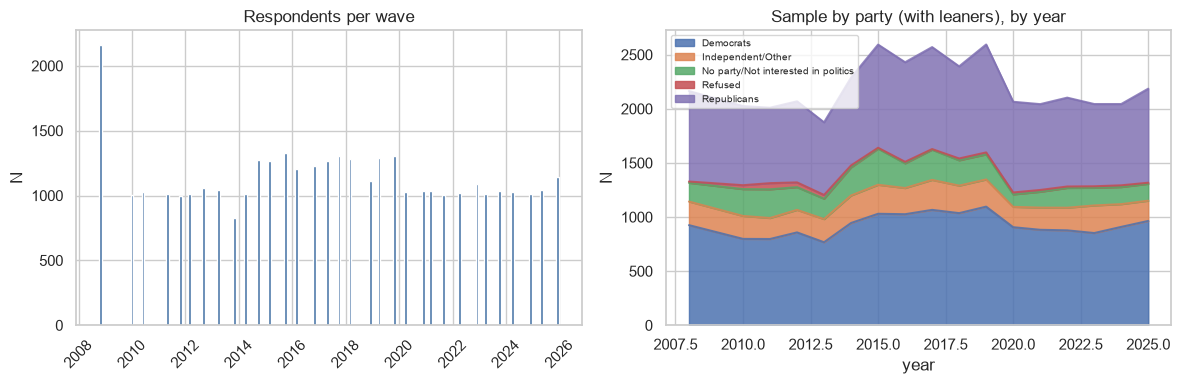

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(waves["wave_date"], waves["n"], width=40, color="#4C78A8")
axes[0].set_title("Respondents per wave")
axes[0].set_ylabel("N")
axes[0].tick_params(axis="x", rotation=45)

comp = (
    ccam.assign(party=ccam["party_w_leaners"].fillna("Refused"))
    .groupby(["year", "party"], as_index=False)
    .size()
)
comp_pivot = comp.pivot(index="year", columns="party", values="size").fillna(0)
comp_pivot.plot(kind="area", stacked=True, ax=axes[1], alpha=0.85)
axes[1].set_title("Sample by party (with leaners), by year")
axes[1].set_ylabel("N")
axes[1].legend(loc="upper left", fontsize=7, title=None)
plt.tight_layout()
plt.show()

## Core beliefs over time
Is it happening? Human-caused? Do scientists agree?

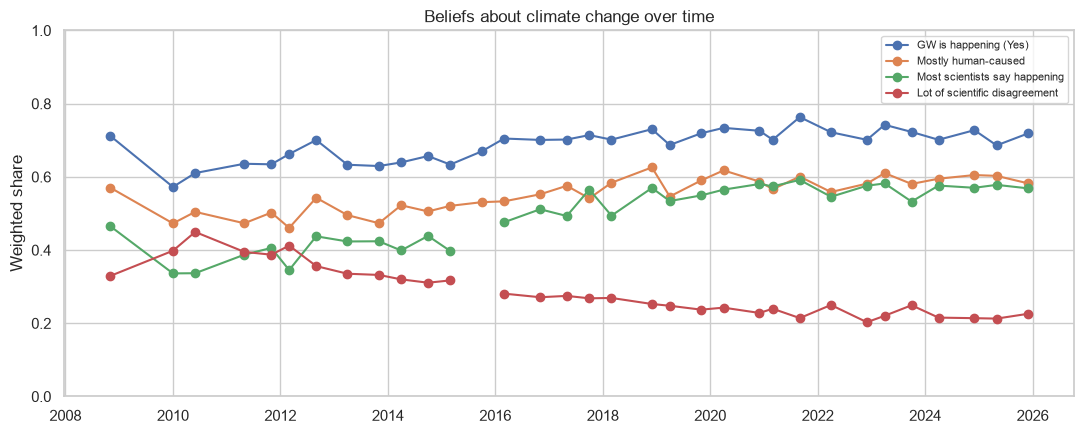

,wave,wave_date,happening_yes,human_caused,sci_agree_happening,sci_disagreement
28,Oct-23,2023-10-01,0.722780,0.580678,0.532424,0.249205
29,Apr-24,2024-04-01,0.701329,0.594975,0.576200,0.215446
30,Dec-24,2024-12-01,0.727622,0.604913,0.570155,0.213917
31,May-25,2025-05-01,0.686045,0.602745,0.578165,0.212739
32,Dec-25,2025-12-01,0.718758,0.582293,0.568593,0.225916


In [4]:
def weighted_share(df: pd.DataFrame, col: str, positive_values: set[str]) -> float:
    s = df[col]
    w = df["weight_wave"]
    mask = s.notna() & w.notna() & ~s.astype(str).str.lower().isin(["refused"])
    if mask.sum() == 0:
        return np.nan
    s = s[mask].astype(str)
    w = w[mask]
    return float((w * s.isin(positive_values).astype(float)).sum() / w.sum())


belief_rows = []
for wave, g in ccam.groupby("wave", sort=False):
    belief_rows.append(
        {
            "wave": wave,
            "wave_date": g["wave_date"].iloc[0],
            "happening_yes": weighted_share(g, "happening", {"Yes"}),
            "human_caused": weighted_share(
                g,
                "cause_recoded",
                {"Caused mostly by human activities"},
            ),
            "sci_agree_happening": weighted_share(
                g,
                "sci_consensus",
                {"Most scientists think global warming is happening"},
            ),
            "sci_disagreement": weighted_share(
                g,
                "sci_consensus",
                {
                    "There is a lot of disagreement among scientists about whether or not global warming is happening"
                },
            ),
        }
    )
beliefs = pd.DataFrame(belief_rows).dropna(subset=["wave_date"]).sort_values("wave_date")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(beliefs["wave_date"], beliefs["happening_yes"], marker="o", label="GW is happening (Yes)")
ax.plot(beliefs["wave_date"], beliefs["human_caused"], marker="o", label="Mostly human-caused")
ax.plot(beliefs["wave_date"], beliefs["sci_agree_happening"], marker="o", label="Most scientists say happening")
ax.plot(beliefs["wave_date"], beliefs["sci_disagreement"], marker="o", label="Lot of scientific disagreement")
ax.set_ylim(0, 1)
ax.set_ylabel("Weighted share")
ax.set_title("Beliefs about climate change over time")
ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()
display(beliefs.tail())

## Concern and risk
Worry, personal vs collective harm, and whether harm is seen as imminent.

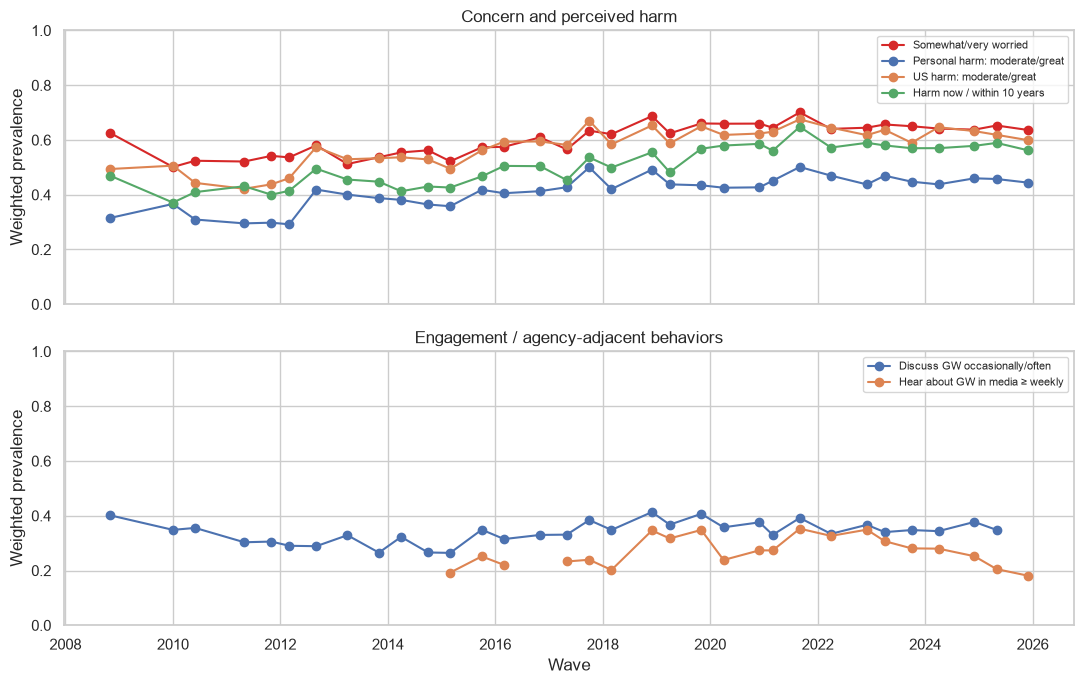

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(waves["wave_date"], waves["worry_high"], marker="o", color="#d62828", label="Somewhat/very worried")
axes[0].plot(waves["wave_date"], waves["harm_personally_high"], marker="o", label="Personal harm: moderate/great")
axes[0].plot(waves["wave_date"], waves["harm_US_high"], marker="o", label="US harm: moderate/great")
axes[0].plot(waves["wave_date"], waves["when_harm_soon"], marker="o", label="Harm now / within 10 years")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Weighted prevalence")
axes[0].set_title("Concern and perceived harm")
axes[0].legend(loc="best", fontsize=8)

axes[1].plot(waves["wave_date"], waves["discuss_often"], marker="o", label="Discuss GW occasionally/often")
axes[1].plot(waves["wave_date"], waves["hear_media_weekly"], marker="o", label="Hear about GW in media ≥ weekly")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Weighted prevalence")
axes[1].set_title("Engagement / agency-adjacent behaviors")
axes[1].legend(loc="best", fontsize=8)
axes[1].set_xlabel("Wave")
plt.tight_layout()
plt.show()

## Policy support
Regulation, clean energy, national priority.

/var/folders/qz/ndsnrxjx0xgbzf96w5x4fx8h0000gn/T/ipykernel_33715/2219044927.py:11: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/Users/lucaslevine/Desktop/project/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


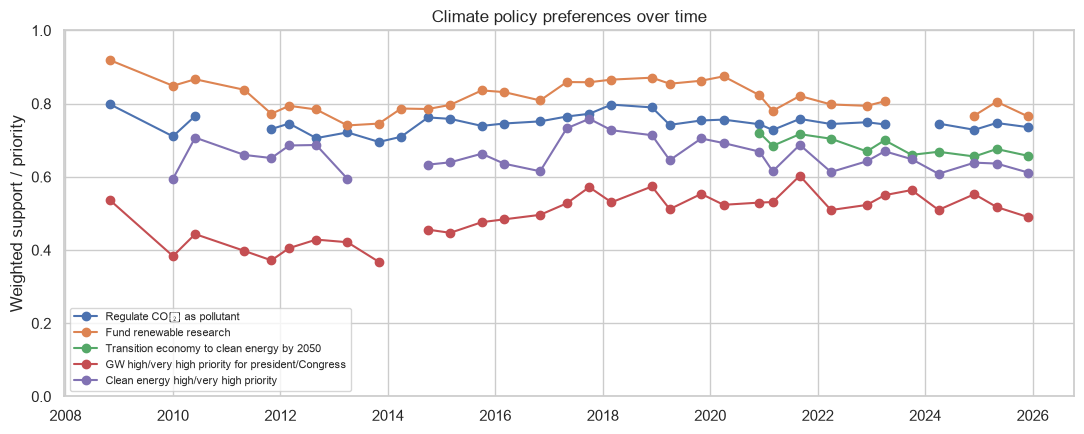

Latest wave snapshot:


,32
wave,Dec-25
wave_date,2025-12-01 00:00:00
year,2025
n,1146
worry_high,0.636424
harm_personally_high,0.44421
harm_US_high,0.59926
when_harm_soon,0.56215
discuss_often,NaN
hear_media_weekly,0.180979


In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(waves["wave_date"], waves["support_CO2_reg"], marker="o", label="Regulate CO₂ as pollutant")
ax.plot(waves["wave_date"], waves["support_fund_research"], marker="o", label="Fund renewable research")
ax.plot(waves["wave_date"], waves["support_transition"], marker="o", label="Transition economy to clean energy by 2050")
ax.plot(waves["wave_date"], waves["priority_high"], marker="o", label="GW high/very high priority for president/Congress")
ax.plot(waves["wave_date"], waves["priority_cleanenergy_high"], marker="o", label="Clean energy high/very high priority")
ax.set_ylim(0, 1)
ax.set_ylabel("Weighted support / priority")
ax.set_title("Climate policy preferences over time")
ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

print("Latest wave snapshot:")
display(waves.sort_values("wave_date").tail(1).T)

## The partisan story
Same outcomes, split by party with leaners — usually the clearest structure in CCAM.

/var/folders/qz/ndsnrxjx0xgbzf96w5x4fx8h0000gn/T/ipykernel_33715/1330120367.py:45: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/Users/lucaslevine/Desktop/project/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


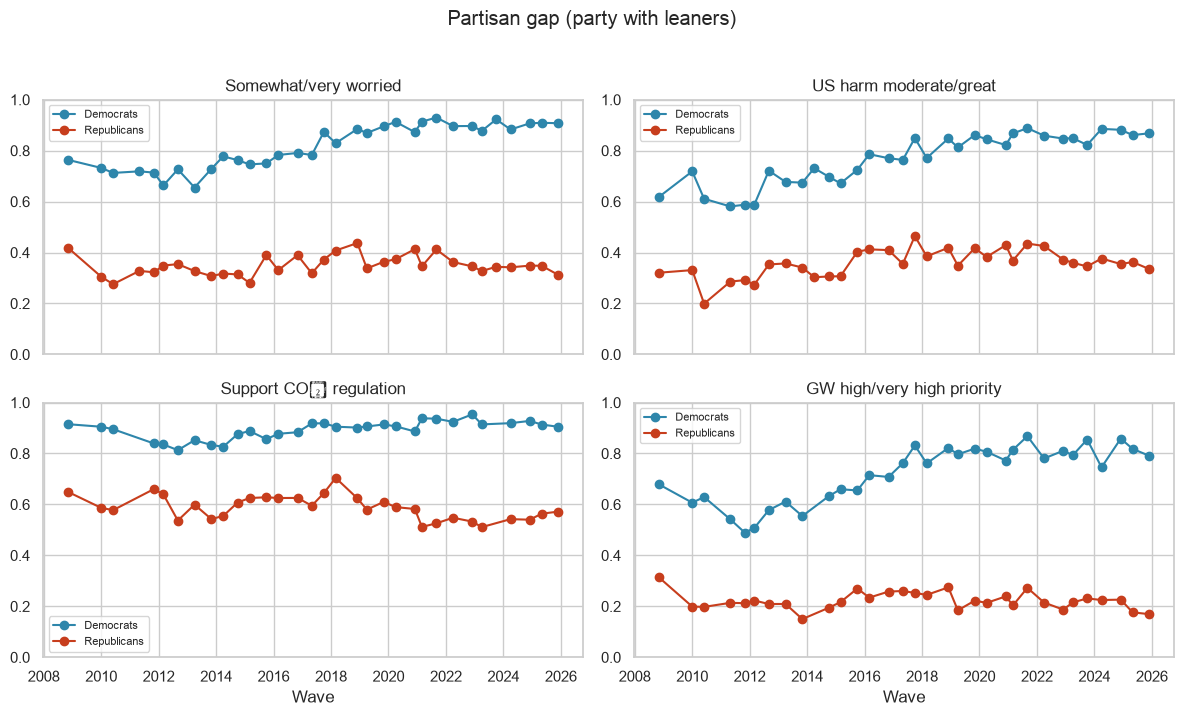

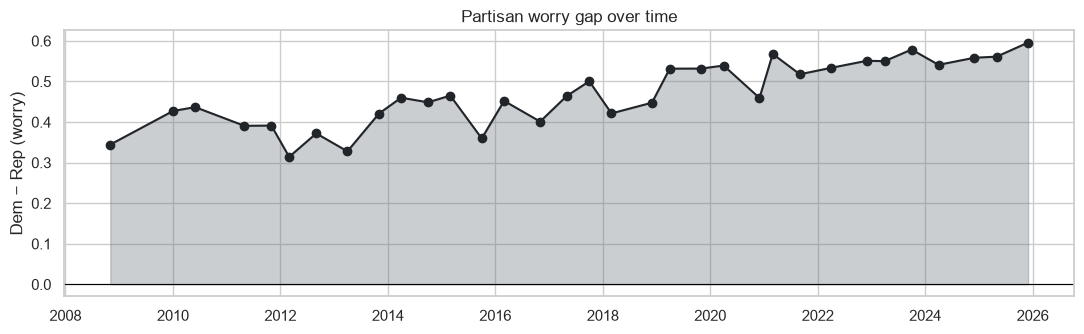

In [7]:
def wave_by_group(df: pd.DataFrame, group_col: str, outcome_col: str, high_value: float = 2) -> pd.DataFrame:
    rows = []
    for (wave, grp), g in df.groupby(["wave", group_col], sort=False):
        if pd.isna(grp) or str(grp).lower() == "refused":
            continue
        s = g[outcome_col]
        w = g["weight_wave"]
        mask = s.notna() & w.notna()
        if mask.sum() == 0:
            continue
        prev = float((w[mask] * (s[mask] == high_value).astype(float)).sum() / w[mask].sum())
        rows.append(
            {
                "wave": wave,
                "wave_date": g["wave_date"].iloc[0],
                "group": grp,
                "prevalence": prev,
                "n": int(mask.sum()),
            }
        )
    return pd.DataFrame(rows).dropna(subset=["wave_date"]).sort_values("wave_date")


party_keep = {"Democrats", "Republicans"}
ccam_party = ccam[ccam["party_w_leaners"].isin(party_keep)].copy()

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
plots = [
    ("worry_r", "Somewhat/very worried", axes[0, 0]),
    ("harm_US_r", "US harm moderate/great", axes[0, 1]),
    ("reg_CO2_pollutant_r", "Support CO₂ regulation", axes[1, 0]),
    ("priority_r", "GW high/very high priority", axes[1, 1]),
]
for col, title, ax in plots:
    d = wave_by_group(ccam_party, "party_w_leaners", col)
    for party, color in [("Democrats", "#2E86AB"), ("Republicans", "#C73E1D")]:
        sub = d[d["group"] == party]
        ax.plot(sub["wave_date"], sub["prevalence"], marker="o", color=color, label=party)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend(fontsize=8)
axes[1, 0].set_xlabel("Wave")
axes[1, 1].set_xlabel("Wave")
fig.suptitle("Partisan gap (party with leaners)", y=1.02)
plt.tight_layout()
plt.show()

# Gap size for worry
worry_party = wave_by_group(ccam_party, "party_w_leaners", "worry_r")
gap = (
    worry_party.pivot(index="wave_date", columns="group", values="prevalence")
    .assign(dem_minus_rep=lambda x: x["Democrats"] - x["Republicans"])
    .reset_index()
)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.fill_between(gap["wave_date"], 0, gap["dem_minus_rep"], color="#6c757d", alpha=0.35)
ax.plot(gap["wave_date"], gap["dem_minus_rep"], color="#212529", marker="o")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Dem − Rep (worry)")
ax.set_title("Partisan worry gap over time")
plt.tight_layout()
plt.show()

## Who is most worried? (latest waves pooled)
Cross-sectional profile using the most recent ~3 waves for stable subgroup Ns.

Pooled waves: ['Dec-24', 'Dec-25', 'May-25']


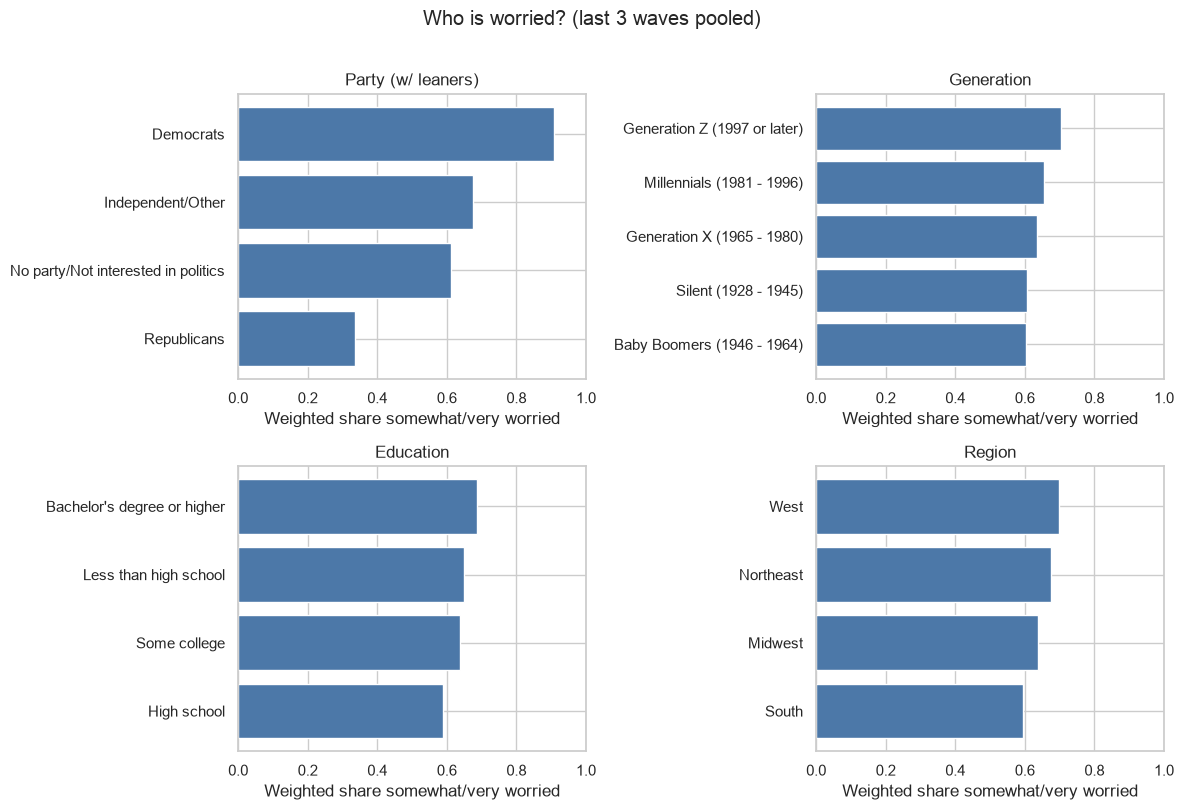

In [8]:
latest_dates = sorted(ccam["wave_date"].dropna().unique())[-3:]
recent = ccam[ccam["wave_date"].isin(latest_dates)].copy()
print("Pooled waves:", sorted(recent["wave"].unique()))


def subgroup_worry(df: pd.DataFrame, col: str) -> pd.DataFrame:
    rows = []
    for grp, g in df.groupby(col):
        if pd.isna(grp) or str(grp).lower() in {"refused", "nan"}:
            continue
        s, w = g["worry_r"], g["weight_wave"]
        mask = s.notna() & w.notna()
        if mask.sum() < 50:
            continue
        rows.append(
            {
                "group": str(grp),
                "n": int(mask.sum()),
                "worry_high": float((w[mask] * (s[mask] == 2).astype(float)).sum() / w[mask].sum()),
            }
        )
    return pd.DataFrame(rows).sort_values("worry_high")


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col, title in [
    (axes[0, 0], "party_w_leaners", "Party (w/ leaners)"),
    (axes[0, 1], "generation", "Generation"),
    (axes[1, 0], "educ_category", "Education"),
    (axes[1, 1], "region4", "Region"),
]:
    d = subgroup_worry(recent, col)
    ax.barh(d["group"], d["worry_high"], color="#4C78A8")
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("Weighted share somewhat/very worried")
plt.suptitle("Who is worried? (last 3 waves pooled)", y=1.01)
plt.tight_layout()
plt.show()

## Ideology × party heatmap (latest pooled waves)
Worry prevalence in the familiar political space.

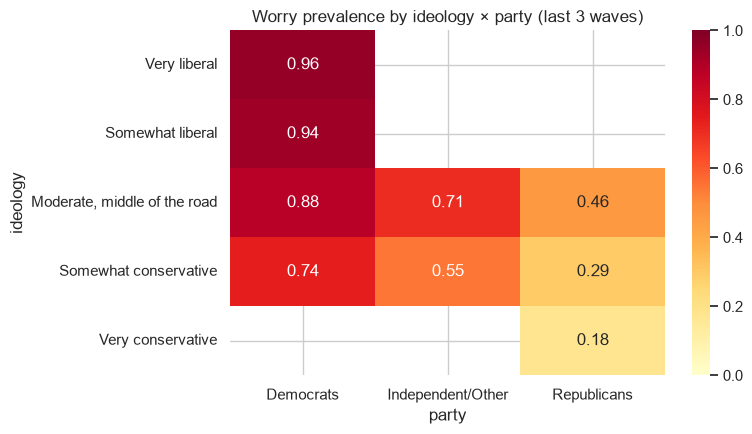

,party,ideology,worry_high,n
3,Democrats,Very liberal,0.956767,248
2,Democrats,Somewhat liberal,0.936450,514
0,Democrats,"Moderate, middle of the road",0.882626,582
1,Democrats,Somewhat conservative,0.739966,61
4,Independent/Other,"Moderate, middle of the road",0.705455,180
5,Independent/Other,Somewhat conservative,0.546218,40
6,Republicans,"Moderate, middle of the road",0.457411,372
7,Republicans,Somewhat conservative,0.294347,553
8,Republicans,Very conservative,0.179064,286


In [9]:
ideo_order = [
    "Very liberal",
    "Somewhat liberal",
    "Moderate, middle of the road",
    "Somewhat conservative",
    "Very conservative",
]
party_order = ["Democrats", "Independent/Other", "Republicans"]

heat_rows = []
for (party, ideo), g in recent.groupby(["party_w_leaners", "ideology"]):
    if party not in party_order or ideo not in ideo_order:
        continue
    s, w = g["worry_r"], g["weight_wave"]
    mask = s.notna() & w.notna()
    if mask.sum() < 40:
        continue
    heat_rows.append(
        {
            "party": party,
            "ideology": ideo,
            "worry_high": float((w[mask] * (s[mask] == 2).astype(float)).sum() / w[mask].sum()),
            "n": int(mask.sum()),
        }
    )
heat = pd.DataFrame(heat_rows)
mat = heat.pivot(index="ideology", columns="party", values="worry_high").reindex(index=ideo_order, columns=party_order)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(mat, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, ax=ax)
ax.set_title("Worry prevalence by ideology × party (last 3 waves)")
plt.tight_layout()
plt.show()
display(heat.sort_values("worry_high", ascending=False))

## One-page summary table
First wave vs latest wave for the headline indicators.

In [10]:
first = waves.sort_values("wave_date").iloc[0]
last = waves.sort_values("wave_date").iloc[-1]
cols = [
    "worry_high",
    "harm_personally_high",
    "harm_US_high",
    "when_harm_soon",
    "discuss_often",
    "support_CO2_reg",
    "support_fund_research",
    "priority_high",
    "priority_cleanenergy_high",
]
summary = pd.DataFrame(
    {
        "indicator": cols,
        f"first ({first['wave']})": [first[c] for c in cols],
        f"latest ({last['wave']})": [last[c] for c in cols],
    }
)
summary["change"] = summary.iloc[:, 2] - summary.iloc[:, 1]
display(summary.style.format({summary.columns[1]: "{:.1%}", summary.columns[2]: "{:.1%}", "change": "{:+.1%}"}))

print(
    f"""
Story sketch (from these series):
- Belief that warming is happening / human-caused is majority territory, with a durable partisan split.
- Worry and "harm is soon" rose after the mid-2010s more than personal-harm perceptions did.
- Many specific policies (CO₂ regulation, renewables research) remain broadly popular even when "priority" is more contested.
- Behaviors like discussing GW stay lower than belief/worry — engagement lags concern.
"""
)

,indicator,first (Nov-08),latest (Dec-25),change
0,worry_high,62.5%,63.6%,+1.1%
1,harm_personally_high,31.5%,44.4%,+12.9%
2,harm_US_high,49.4%,59.9%,+10.5%
3,when_harm_soon,46.9%,56.2%,+9.3%
4,discuss_often,40.1%,nan%,+nan%
5,support_CO2_reg,79.8%,73.6%,-6.2%
6,support_fund_research,91.9%,76.5%,-15.4%
7,priority_high,53.6%,49.0%,-4.5%
8,priority_cleanenergy_high,nan%,61.2%,+nan%



Story sketch (from these series):
- Belief that warming is happening / human-caused is majority territory, with a durable partisan split.
- Worry and "harm is soon" rose after the mid-2010s more than personal-harm perceptions did.
- Many specific policies (CO₂ regulation, renewables research) remain broadly popular even when "priority" is more contested.
- Behaviors like discussing GW stay lower than belief/worry — engagement lags concern.

